# Linear AR + Conformal Prediction

Linear regression on the last 5 lagged log-returns wrapped with split-conformal, ACI (Gibbs & Candès 2021), and AgACI (Zaffran et al. 2022).  See `src/analysis/Simple_CP/README.md`.

**Workflow.** This notebook (i) runs `linear_ar` × `['split', 'aci', 'agaci']` on every `(ticker, regime)` cell — *idempotently*, skipping cells whose CSV already exists in `results/`; (ii) loads those CSVs and writes a per-cell timeline figure into `report/figures/timelines/Simple_CP/`; (iii) prints a per-cell metrics table and a summary aggregated by wrapper.

In [1]:
# sys.path bootstrap so 'from src...' works regardless of CWD
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project root:", ROOT)


project root: \\wsl.localhost\Ubuntu\home\jsarin\conformalQuant


In [2]:
import warnings, glob, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.analysis._shared import (
    RESULTS_DIR, CRISIS_WINDOWS, MODEL_CATEGORIES,
    ensure_data, iterate_experiments, walk_forward, save_intervals, make_wrapper,
)
from src.plotting import plot_interval_timeline, compute_cell_metrics, render_cell_grid

FORCE_RERUN = False  # set True to ignore cached CSVs and re-run every cell


## 1. Run `linear_ar` × `['split', 'aci', 'agaci']` (idempotent)

In [3]:
import torch
from src.models.linear_ar import LinearARModel
data = ensure_data()
print(f"data: {len(data):,} rows  |  {data.index.min().date()} -> {data.index.max().date()}")

MODEL_NAME = "linear_ar"
MODEL_CLASS = LinearARModel
WRAPPERS = ['split', 'aci', 'agaci']
NUM_LAGS = 5
CONFIDENCE_LEVEL = 0.90
ACI_STEP_SIZE = 0.01
print(f"\nRunning {MODEL_NAME} × {WRAPPERS} on every (ticker, regime) cell ...")

for split in iterate_experiments():
    train = split.slice_train(data); calib = split.slice_calib(data); full = split.slice_full(data)
    if len(train) < NUM_LAGS + 50:
        print(f"  skip {split.regime} {split.ticker.value} — only {len(train)} train rows")
        continue
    for kind in WRAPPERS:
        out = RESULTS_DIR / f"{MODEL_NAME}_{kind}_{split.ticker.value}_{split.regime}.csv"
        if out.exists() and not FORCE_RERUN:
            print(f"  cached  {split.regime} {split.ticker.value:5s} {kind}")
            continue
        np.random.seed(0); torch.manual_seed(0)
        t0 = time.perf_counter()
        try:
            wrapper = make_wrapper(MODEL_CLASS, label_col=split.label_col, num_lags=NUM_LAGS,
                                    confidence_level=CONFIDENCE_LEVEL, wrapper_kind=kind,
                                    step_size=ACI_STEP_SIZE)
            wrapper.fit_and_calibrate(train, calib)
            intervals = walk_forward(wrapper, full, split.test_start, split.test_end)
            save_intervals(intervals, MODEL_NAME, kind, split.ticker, split.regime)
            cell = compute_cell_metrics(intervals)
            print(f"  {split.regime} {split.ticker.value:5s} {kind:6s}: "
                  f"cov={cell['cov']:.3f}  W={cell['winkler']:.3f}  width={cell['width']:.4f}  "
                  f"({time.perf_counter()-t0:.1f}s)")
        except Exception as e:
            print(f"  {split.regime} {split.ticker.value:5s} {kind:6s}: SKIPPED ({type(e).__name__}: {e})")
            if out.exists(): out.unlink()


data: 5,863 rows  |  2003-01-03 -> 2026-04-23

Running linear_ar × ['split', 'aci', 'agaci'] on every (ticker, regime) cell ...
  cached  2008 AIG   split
  cached  2008 AIG   aci
  cached  2008 AIG   agaci
  cached  2008 GNW   split
  cached  2008 GNW   aci
  cached  2008 GNW   agaci
  cached  2008 MGM   split
  cached  2008 MGM   aci
  cached  2008 MGM   agaci
  cached  2020 MCD   split
  cached  2020 MCD   aci
  cached  2020 MCD   agaci
  cached  2020 MGM   split
  cached  2020 MGM   aci
  cached  2020 MGM   agaci
  cached  2020 AZO   split
  cached  2020 AZO   aci
  cached  2020 AZO   agaci
  cached  2022 SNAP  split
  cached  2022 SNAP  aci
  cached  2022 SNAP  agaci
  cached  2022 NFLX  split
  cached  2022 NFLX  aci
  cached  2022 NFLX  agaci
  cached  2022 META  split
  cached  2022 META  aci
  cached  2022 META  agaci


## 2. Render timeline figures, one per cell

In [4]:
CATEGORY = "Simple_CP"
MODEL_NAME = "linear_ar"
import pathlib
out_dir = ROOT / "report" / "figures" / "timelines" / CATEGORY
patterns = [str(RESULTS_DIR / f"{MODEL_NAME}_*_*.csv")]
files = sorted({f for p in patterns for f in glob.glob(p)})
files = [f for f in files if pathlib.Path(f).name.startswith(f"{MODEL_NAME}_")]
if not files:
    raise RuntimeError(f"no CSVs for model={MODEL_NAME!r}; did the run cell finish?")
raw = pd.concat([pd.read_csv(f, parse_dates=["date"]) for f in files], ignore_index=True)
raw = raw[raw["model"] == MODEL_NAME]
metrics = render_cell_grid(
    raw, model_filter=[MODEL_NAME], out_dir=out_dir,
    crisis_windows=CRISIS_WINDOWS, category_lookup=MODEL_CATEGORIES,
)
print(f"wrote {len(metrics)} timeline figures → {out_dir.relative_to(ROOT)}")
metrics_sorted = metrics.sort_values(["wrapper", "regime", "ticker"]).reset_index(drop=True)
display(metrics_sorted.round(3))


wrote 27 timeline figures → report\figures\timelines\Simple_CP


,model,wrapper,ticker,regime,cov,winkler,width,n
0,linear_ar,aci,AIG,2008,0.779,0.597,0.188,390
1,linear_ar,aci,GNW,2008,0.708,0.659,0.157,390
2,linear_ar,aci,MGM,2008,0.690,0.480,0.131,390
3,linear_ar,aci,AZO,2020,0.872,0.104,0.054,304
4,linear_ar,aci,MCD,2020,0.832,0.112,0.038,304
5,linear_ar,aci,MGM,2020,0.819,0.251,0.093,304
6,linear_ar,aci,META,2022,0.892,0.150,0.089,501
7,linear_ar,aci,NFLX,2022,0.896,0.154,0.096,501
8,linear_ar,aci,SNAP,2022,0.904,0.261,0.148,501
9,linear_ar,agaci,AIG,2008,0.769,0.606,0.178,390


## 3. Summary aggregated by wrapper


linear_ar — average across all 9 (ticker, regime) cells (lower Winkler = better)


,cov,winkler,width
wrapper,,,
aci,0.821,0.307,0.110
agaci,0.812,0.312,0.105
split,0.680,0.408,0.071



Representative figure (linear_ar_aci_AIG_2008.png):


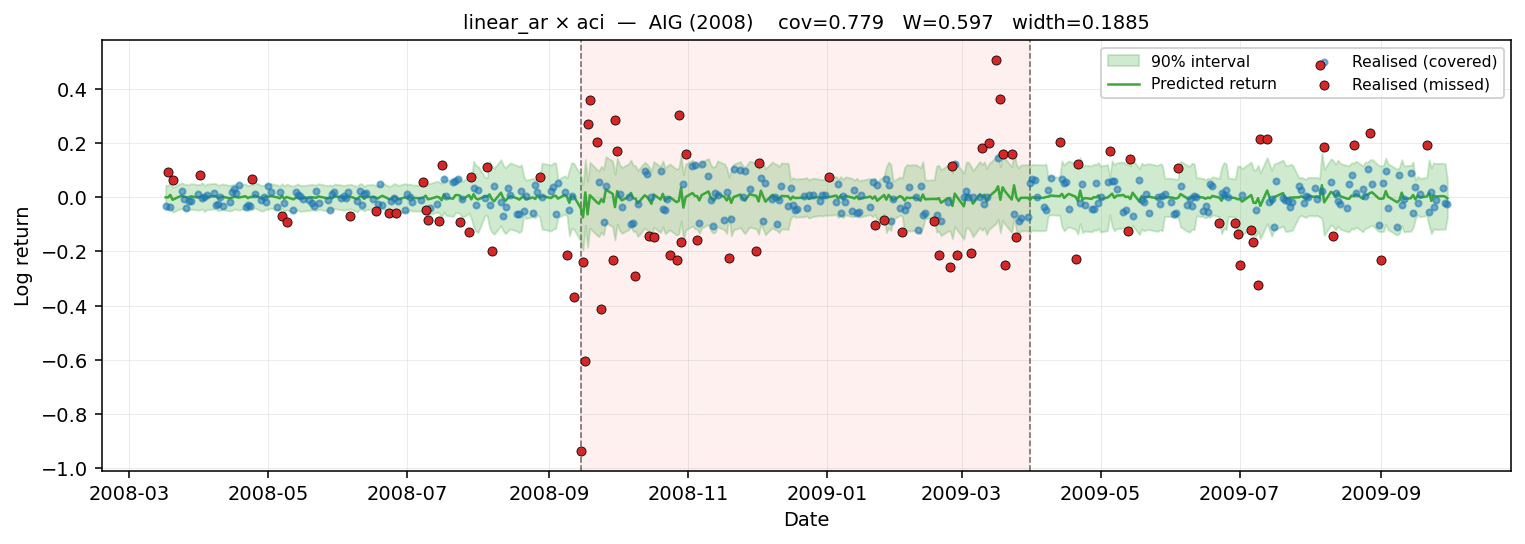

In [5]:
# Aggregate by wrapper — mean across all (ticker, regime) cells
summary = (
    metrics_sorted
    .groupby("wrapper")[["cov", "winkler", "width"]]
    .mean()
    .sort_values("winkler")
    .round(3)
)
print(f"\n{MODEL_NAME} — average across all 9 (ticker, regime) cells (lower Winkler = better)")
display(summary)

# Show one representative figure inline
sample = sorted((ROOT / "report" / "figures" / "timelines" / CATEGORY).glob(f"{MODEL_NAME}_*.png"))
if sample:
    print(f"\nRepresentative figure ({sample[0].name}):")
    display(Image(filename=str(sample[0])))
